In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

In [4]:
data = pd.read_csv("/content/drive/MyDrive/train.csv", on_bad_lines='skip')
data.head()

,timestamp,active_power_calculated_by_converter,active_power_raw,ambient_temperature,generator_speed,generator_winding_temp_max,grid_power10min_average,nc1_inside_temp,nacelle_temp,reactice_power_calculated_by_converter,reactive_power,wind_direction_raw,wind_speed_raw,wind_speed_turbulence,turbine_id,Target
0,19-02-2021 20:18,816.636759,834.917206,31.694380,1159.616602,65.954214,917.897085,31.881972,31.504713,141.457644,165.501518,280.864782,7.057000,0.544082,Turbine_108,47.582787
1,27-04-2021 04:55,419.107829,421.050873,12.894948,928.747996,59.571319,445.554250,32.423705,32.755770,89.186457,113.835236,299.552460,5.474937,0.469031,Turbine_18,46.070328
2,25-01-2021 06:26,1303.530558,1337.566142,16.648388,1201.219775,61.270498,1364.716003,11.446849,18.332985,230.622309,281.452253,84.960106,8.092457,0.622318,Turbine_105,39.989236
3,30-10-2021 03:47,61.494872,53.481008,28.388141,769.806122,40.674348,14.324897,34.253204,32.662889,66.211015,75.017531,87.261119,4.071032,0.760719,Turbine_15,46.056587
4,15-03-2021 00:39,593.514364,611.659109,31.519527,1046.916768,64.341763,599.020172,32.405586,31.466387,137.163938,160.202421,313.724818,6.357943,0.346068,Turbine_01,54.346095


In [5]:
data = data.drop("timestamp", axis=1) # Since not useful for ml

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 909604 entries, 0 to 909603
Data columns (total 15 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   active_power_calculated_by_converter    909604 non-null  float64
 1   active_power_raw                        909604 non-null  float64
 2   ambient_temperature                     909604 non-null  float64
 3   generator_speed                         909604 non-null  float64
 4   generator_winding_temp_max              909604 non-null  float64
 5   grid_power10min_average                 909604 non-null  float64
 6   nc1_inside_temp                         909604 non-null  float64
 7   nacelle_temp                            909604 non-null  float64
 8   reactice_power_calculated_by_converter  909604 non-null  float64
 9   reactive_power                          909604 non-null  float64
 10  wind_direction_raw                      9096

In [8]:
data.isnull().sum()

,0
active_power_calculated_by_converter,0
active_power_raw,0
ambient_temperature,0
generator_speed,0
generator_winding_temp_max,0
grid_power10min_average,0
nc1_inside_temp,0
nacelle_temp,0
reactice_power_calculated_by_converter,0
reactive_power,0


In [9]:
data.dropna(inplace=True) # Since the data is large so we can ignore those small number of rows

In [10]:
data.isnull().sum()

,0
active_power_calculated_by_converter,0
active_power_raw,0
ambient_temperature,0
generator_speed,0
generator_winding_temp_max,0
grid_power10min_average,0
nc1_inside_temp,0
nacelle_temp,0
reactice_power_calculated_by_converter,0
reactive_power,0


In [11]:
correlation=data.corr(numeric_only=True)

<Axes: >

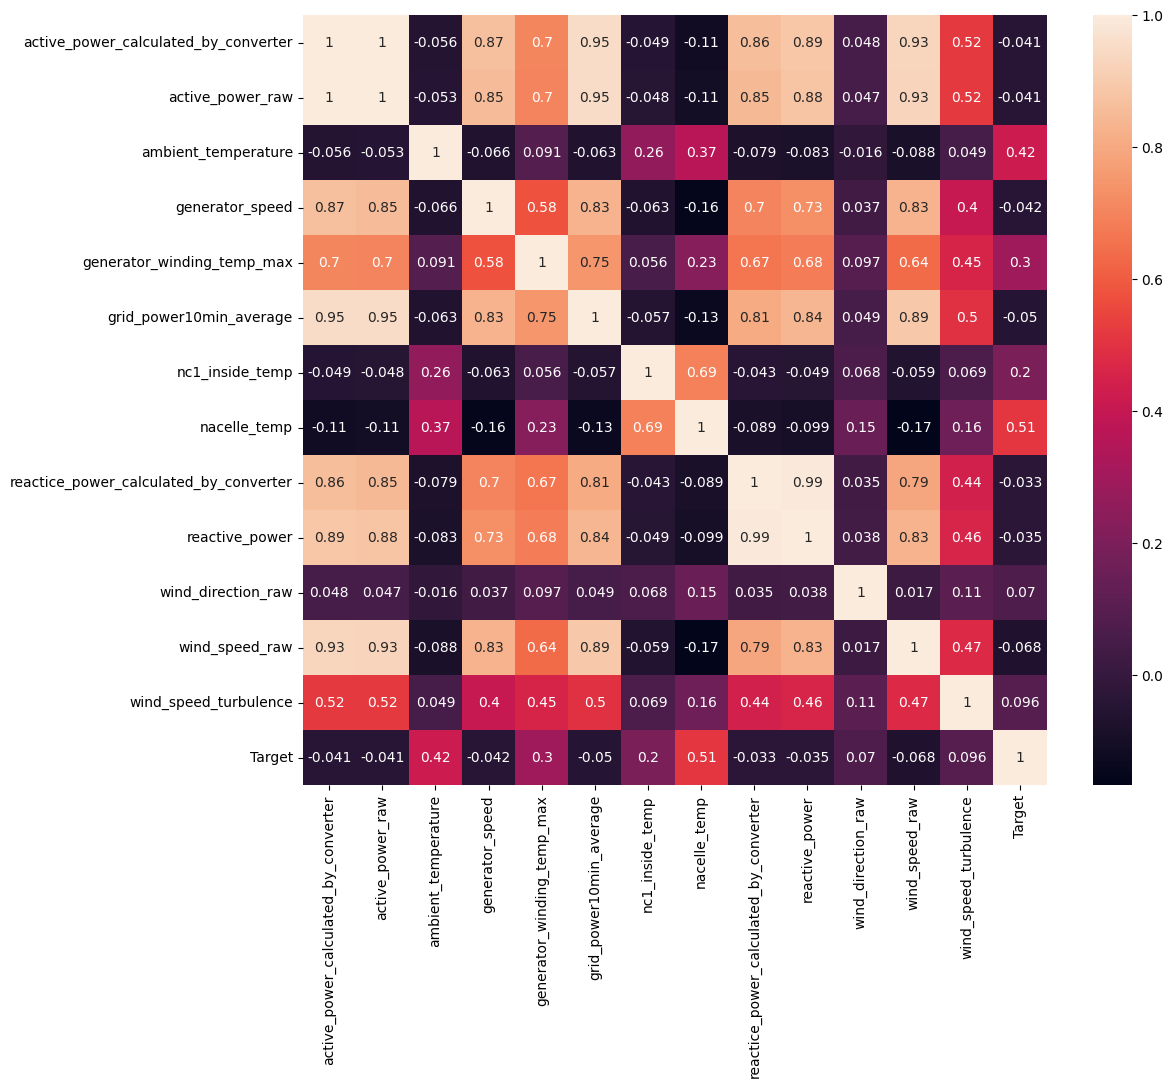

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 10))
sns.heatmap(correlation,annot=True)

In [13]:
columns_to_drop = [
    'active_power_raw',
    'reactive_power',
    'grid_power10min_average'
]


data = data.drop(columns=columns_to_drop,axis=1)


data.head(1)

,active_power_calculated_by_converter,ambient_temperature,generator_speed,generator_winding_temp_max,nc1_inside_temp,nacelle_temp,reactice_power_calculated_by_converter,wind_direction_raw,wind_speed_raw,wind_speed_turbulence,turbine_id,Target
0,816.636759,31.69438,1159.616602,65.954214,31.881972,31.504713,141.457644,280.864782,7.057,0.544082,Turbine_108,47.582787


In [14]:
data.dtypes

,0
active_power_calculated_by_converter,float64
ambient_temperature,float64
generator_speed,float64
generator_winding_temp_max,float64
nc1_inside_temp,float64
nacelle_temp,float64
reactice_power_calculated_by_converter,float64
wind_direction_raw,float64
wind_speed_raw,float64
wind_speed_turbulence,float64


In [15]:
X = data.drop("Target", axis=1)
y = data["Target"]

In [16]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 909604 entries, 0 to 909603
Data columns (total 11 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   active_power_calculated_by_converter    909604 non-null  float64
 1   ambient_temperature                     909604 non-null  float64
 2   generator_speed                         909604 non-null  float64
 3   generator_winding_temp_max              909604 non-null  float64
 4   nc1_inside_temp                         909604 non-null  float64
 5   nacelle_temp                            909604 non-null  float64
 6   reactice_power_calculated_by_converter  909604 non-null  float64
 7   wind_direction_raw                      909604 non-null  float64
 8   wind_speed_raw                          909604 non-null  float64
 9   wind_speed_turbulence                   909604 non-null  float64
 10  turbine_id                              9096

In [17]:
# 1. List all numeric columns
numeric_cols = [
    "active_power_calculated_by_converter",
    "ambient_temperature",
    "generator_speed",
    "generator_winding_temp_max",
    "nc1_inside_temp",
    "nacelle_temp",
    "reactice_power_calculated_by_converter",
    "wind_direction_raw",
    "wind_speed_raw",
    "wind_speed_turbulence"
]

# 2. CLEAN
for col in numeric_cols:
    X[col] = (
        X[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.replace(" ", "", regex=False)
        .astype(float)
    )

# 3. Convert turbine_id to category codes
X["turbine_id"] = X["turbine_id"].astype("category").cat.codes

print("After cleaning:")
print(X.info())


After cleaning:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 909604 entries, 0 to 909603
Data columns (total 11 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   active_power_calculated_by_converter    909604 non-null  float64
 1   ambient_temperature                     909604 non-null  float64
 2   generator_speed                         909604 non-null  float64
 3   generator_winding_temp_max              909604 non-null  float64
 4   nc1_inside_temp                         909604 non-null  float64
 5   nacelle_temp                            909604 non-null  float64
 6   reactice_power_calculated_by_converter  909604 non-null  float64
 7   wind_direction_raw                      909604 non-null  float64
 8   wind_speed_raw                          909604 non-null  float64
 9   wind_speed_turbulence                   909604 non-null  float64
 10  turbine_id                  

In [18]:
X = X.apply(pd.to_numeric, errors='coerce')
X = X.fillna(method='ffill')

/tmp/ipython-input-3846115005.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  X = X.fillna(method='ffill')


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [20]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from xgboost import XGBRegressor



In [21]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [22]:
model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)


In [23]:
model.fit(X_train_scaled, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=None, num_parallel_tree=None, ...)

In [24]:
y_pred = model.predict(X_test_scaled)

In [25]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("MAE:", mae)
print("RMSE:", rmse)
print("MSE:", mse)
print("R² Score:", r2)

MAE: 0.9358979847467365
RMSE: 1.3846927362937442
MSE: 1.9173739739446567
R² Score: 0.7192277614553672
